In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
rdf_path = "/content/drive/MyDrive/Data_File_Collected_Data_for_KG_in_RDF_Triples.rdf"

In [3]:
# Clone repository
!git clone https://github.com/THUDM/CogKR

# Check if utils.py exists
!ls CogKR/src/utils.py

Cloning into 'CogKR'...
remote: Enumerating objects: 582, done.
remote: Counting objects: 100% (470/470), done.
remote: Compressing objects: 100% (130/130), done.
remote: Total 582 (delta 344), reused 451 (delta 340), pack-reused 112 (from 1)
Receiving objects: 100% (582/582), 142.04 KiB | 1.84 MiB/s, done.
Resolving deltas: 100% (411/411), done.
CogKR/src/utils.py


In [4]:
!grep -n "def load_index" CogKR/src/utils.py -A 10

29:def load_index(path):
30-    name2ids = {}
31-    with open(path) as file:
32-        for i, line in enumerate(file):
33-            line = line.strip().split()
34-            if len(line) == 1:
35-                name2ids[line[0]] = i
36-            else:
37-                idx, name = line
38-                name2ids[name] = int(idx)
39-    return name2ids


In [5]:
!pip install rdflib tqdm numpy scipy

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 615.4/615.4 kB 3.1 MB/s eta 0:00:00


In [6]:
import rdflib
import os
import random

# ---- CONFIGURATION ----
rdf_path = "/content/drive/MyDrive/Data_File_Collected_Data_for_KG_in_RDF_Triples.rdf"  # adjust if needed
output_dir = "CogKR/datasets/learning_style/data"
os.makedirs(output_dir, exist_ok=True)

# ---- Load RDF ----
g = rdflib.Graph()
g.parse(rdf_path, format="xml")

# ---- Collect data ----
student_uris = set()
answer_codes = set()
relations = set()
triples = []

for s, p, o in g:
    if not isinstance(o, rdflib.Literal):
        continue
    student_uris.add(s)
    answer_codes.add(str(o))
    relations.add(p)
    triples.append((s, p, str(o)))

# ---- Create entity IDs ----
# Student short names
student_list = sorted(student_uris, key=str)
student_ids = {str(uri): f"s{i}" for i, uri in enumerate(student_list)}

# Entity mapping: we will later decide order based on load_index expectation
# For now, create mapping with name -> id
ent2id = {}
for sid in student_ids.values():
    ent2id[sid] = len(ent2id)
for code in sorted(answer_codes):
    ent2id[code] = len(ent2id)

# Relation mapping
rel2id = {str(rel): i for i, rel in enumerate(sorted(relations, key=str))}

# ---- Write files in the format that load_index expects ----
# We need to inspect the load_index function first.
# TEMPORARY: write as name\tid (most common). If it fails, we'll swap.
with open(os.path.join(output_dir, "ent2id.txt"), "w") as f:
    for name, idx in ent2id.items():
        f.write(f"{name}\t{idx}\n")

with open(os.path.join(output_dir, "relation2id.txt"), "w") as f:
    for name, idx in rel2id.items():
        f.write(f"{name}\t{idx}\n")

# Write all triples
with open(os.path.join(output_dir, "all_triples.txt"), "w") as f:
    for s, p, o in triples:
        s_name = student_ids[str(s)]
        s_id = ent2id[s_name]
        p_id = rel2id[str(p)]
        o_id = ent2id[o]
        f.write(f"{s_id}\t{p_id}\t{o_id}\n")

print("Files created.")
print("First lines of ent2id.txt:")
!head -3 {output_dir}/ent2id.txt
print("First lines of relation2id.txt:")
!head -3 {output_dir}/relation2id.txt

Files created.
First lines of ent2id.txt:
s0	0
s1	1
s2	2
First lines of relation2id.txt:
C:/Users/Administrator/Downloads/Test/FSLSM27Jan24.rdf#During_the_group_study_on_algorithms	0
C:/Users/Administrator/Downloads/Test/FSLSM27Jan24.rdf#For_entertainment_I_prefer_to	1
C:/Users/Administrator/Downloads/Test/FSLSM27Jan24.rdf#How_can_I_effectively_learn	2


In [7]:
def swap_columns(filepath):
    with open(filepath, "r") as f:
        lines = f.readlines()
    with open(filepath, "w") as f:
        for line in lines:
            parts = line.strip().split("\t")
            if len(parts) == 2:
                f.write(f"{parts[1]}\t{parts[0]}\n")
            else:
                f.write(line)

swap_columns(os.path.join(output_dir, "ent2id.txt"))
swap_columns(os.path.join(output_dir, "relation2id.txt"))
print("Columns swapped.")

Columns swapped.


In [8]:
# Load all triples
with open(os.path.join(output_dir, "all_triples.txt"), "r") as f:
    all_triples = [line.strip() for line in f if line.strip()]

random.shuffle(all_triples)

train_ratio = 0.8
valid_ratio = 0.1
test_ratio = 0.1

train_end = int(len(all_triples) * train_ratio)
valid_end = train_end + int(len(all_triples) * valid_ratio)

train = all_triples[:train_end]
valid = all_triples[train_end:valid_end]
test = all_triples[valid_end:]

with open(os.path.join(output_dir, "train.txt"), "w") as f:
    f.write("\n".join(train))
with open(os.path.join(output_dir, "valid_eval.txt"), "w") as f:
    f.write("\n".join(valid))
with open(os.path.join(output_dir, "test_eval.txt"), "w") as f:
    f.write("\n".join(test))
with open(os.path.join(output_dir, "valid_support.txt"), "w") as f:
    f.write("")
with open(os.path.join(output_dir, "test_support.txt"), "w") as f:
    f.write("")

print(f"Train: {len(train)}, Valid: {len(valid)}, Test: {len(test)}")

Train: 5442, Valid: 680, Test: 681


In [9]:
with open(os.path.join(output_dir, "rel2candidates.json"), "w") as f:
    f.write("{}")

In [10]:
!pip install tqdm numpy scipy

In [11]:
import re

file_path = "/content/CogKR/src/preprocess.py"
with open(file_path, "r") as f:
    content = f.read()

# Replace the problematic line with a safe version using .get()
pattern = r'self\.pagerank\s*=\s*\[self\.pagerank\[entity\]\s+for\s+entity\s+in\s+range\(len\(self\.pagerank\)\)\]'
replacement = 'self.pagerank = [self.pagerank.get(entity, 0) for entity in range(len(self.pagerank))]'

new_content = re.sub(pattern, replacement, content)

with open(file_path, "w") as f:
    f.write(new_content)

print("Patched compute_pagerank")

Patched compute_pagerank


In [12]:
!python /content/CogKR/src/preprocess.py --directory /content/CogKR/datasets/learning_style --process_data --save_train

Load rel2candidates
Load preprocessed entity index
Load preprocessed relation index
Begin to compute pagerank
Begin to save pagerank
Complete save pagerank


In [13]:
%cd /content/CogKR

/content/CogKR


In [14]:
%%writefile configs/learning_style.yml
dataset: learning_style
embedding_dim: 50
batch_size: 64
max_epochs: 100
learning_rate: 0.001
num_workers: 2
use_gpu: true

Writing configs/learning_style.yml


In [15]:
!pip install tensorboardX

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 87.5/87.5 kB 1.0 MB/s eta 0:00:00


In [16]:
!pip install torch-scatter -f https://data.pyg.org/whl/torch-2.2.0+cu121.html

Looking in links: https://data.pyg.org/whl/torch-2.2.0+cu121.html
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.9/10.9 MB 21.1 MB/s eta 0:00:00


In [17]:
!pip uninstall torch-scatter -y

Found existing installation: torch_scatter 2.1.2+pt22cu121
Uninstalling torch_scatter-2.1.2+pt22cu121:
  Successfully uninstalled torch_scatter-2.1.2+pt22cu121


In [18]:
!pip install git+https://github.com/rusty1s/pytorch_scatter.git

  Cloning https://github.com/rusty1s/pytorch_scatter.git to /tmp/pip-req-build-jl89a6of
  Running command git clone --filter=blob:none --quiet https://github.com/rusty1s/pytorch_scatter.git /tmp/pip-req-build-jl89a6of
  Resolved https://github.com/rusty1s/pytorch_scatter.git to commit f514c10f920b5aeed2eb162092f0ad20d3edee52
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for torch_scatter: filename=torch_scatter-2.1.2-cp312-cp312-linux_x86_64.whl size=684334 sha256=8061c627fd2641beb063e7cb8109b62fac555f28a09896a769e86f0018217794
  Stored in directory: /tmp/pip-ephem-wheel-cache-_28uhqgp/wheels/88/57/18/06f72b99baee4ab1410454a0c9dd6028f56b238f17508889b0
Successfully built torch_scatter


In [19]:
!pip install torch-scatter --no-binary torch-scatter

In [20]:
!find /content/CogKR -name "*.pkl"

In [21]:
import yaml

# Replace the unserialize call with yaml load
with open("/content/CogKR/src/main.py", "r") as f:
    content = f.read()

# Find the line with "unserialize(args.config)" and replace it
# We'll do a simple replacement
new_content = content.replace("main_body.update_config(unserialize(args.config))",
                              "main_body.update_config(yaml.safe_load(open(args.config)))")

# Also add import yaml at top if not present
if "import yaml" not in new_content:
    new_content = "import yaml\n" + new_content

with open("/content/CogKR/src/main.py", "w") as f:
    f.write(new_content)

print("Patched main.py to use YAML config")

Patched main.py to use YAML config


In [22]:
!cat /content/CogKR/configs/config-wn18rr.json

{
  "graph": {
    "train_width": 256,
    "add_self_loop": true
  },
  "model": {
    "message": true,
    "max_steps": 5,
    "max_nodes": 132,
    "max_neighbors": 10,
    "embed_size": 100,
    "hidden_size": 200,
    "topk": 32,
    "reward_policy": "direct",
    "baseline_lambda": 0.05
  },
  "optimizer": {
    "name": "Adam",
    "embed": {
      "lr": 1e-3
    },
    "summary": {
      "lr": 1e-4
    },
    "agent": {
      "lr": 1e-3
    },
    "config": {
      "weight_decay": 1e-4
    }
  },
  "pretrain_optimizer": {
    "lr": 0.0001
  },
  "trainer": {
    "weighted_sample": true,
    "ignore_onehop": false,
    "meta_learn": false,
    "sample_weight": 1.0,
    "rollout_num": 1,
    "test_rollout_num": 1
  },
  "train": {
    "batch_size": 42,
    "test_batch_size": 84,
    "log_interval": 50,
    "evaluate_interval": 100,
    "max_steps": 30000,
    "entropy_beta": 0.05
  },
  "pretrain": {
    "batch_size": 64
  }
}

In [23]:
%%writefile configs/learning_style.json
{
  "graph": {
    "train_width": 256,
    "add_self_loop": true
  },
  "model": {
    "message": true,
    "max_steps": 5,
    "max_nodes": 200,
    "max_neighbors": 10,
    "embed_size": 50,
    "hidden_size": 100,
    "topk": 32,
    "reward_policy": "direct",
    "baseline_lambda": 0.05
  },
  "optimizer": {
    "name": "Adam",
    "embed": {
      "lr": 0.001
    },
    "summary": {
      "lr": 0.0001
    },
    "agent": {
      "lr": 0.001
    },
    "config": {
      "weight_decay": 1e-4
    }
  },
  "pretrain_optimizer": {
    "lr": 0.0001
  },
  "trainer": {
    "weighted_sample": true,
    "ignore_onehop": false,
    "meta_learn": false,
    "sample_weight": 1.0,
    "rollout_num": 1,
    "test_rollout_num": 1
  },
  "train": {
    "batch_size": 64,
    "test_batch_size": 128,
    "log_interval": 50,
    "evaluate_interval": 100,
    "max_steps": 30000,
    "entropy_beta": 0.05
  },
  "pretrain": {
    "batch_size": 64
  }
}

Writing configs/learning_style.json


In [24]:
import json

with open("/content/CogKR/src/main.py", "r") as f:
    content = f.read()

# Replace the unserialize call with json.load
new_content = content.replace("main_body.update_config(unserialize(args.config))",
                              "main_body.update_config(json.load(open(args.config)))")

# Add import json if not present
if "import json" not in new_content:
    new_content = "import json\n" + new_content

with open("/content/CogKR/src/main.py", "w") as f:
    f.write(new_content)

print("Patched main.py to use JSON config")

Patched main.py to use JSON config


In [25]:
!grep -n "self.reverse_relation" /content/CogKR/src/main.py -A 2 -B 2

139-            self.relation_dict['SELF_LOOP'] = len(self.relation_dict)
140-            self_loop_id = self.relation_dict['SELF_LOOP']
141:        self.reverse_relation = [self.relation_dict[inverse_relation(relation)] for relation in self.id2relation]
142-        self.kg = KG(self.facts_data, entity_num=len(self.entity_dict), relation_num=len(self.relation_dict),
143-                     node_scores=self.pagerank, build_matrix=build_matrix, self_loop_id=self_loop_id, **graph_config)
144:        self.trainer = Trainer(self.kg, self.facts_data, reverse_relation=self.reverse_relation, cutoff=3,
145-                               validate_tasks=(self.valid_support, self.valid_eval),
146-                               test_tasks=(self.test_support, self.test_eval),
--
420-            deleted_edges = []
421-            if ignore_relation:
422:                reverse_relation = self.reverse_relation[relation]
423-                for head, tail in itertools.chain(pairs, self.trainer.train_s

In [26]:
import re

with open("/content/CogKR/src/main.py", "r") as f:
    content = f.read()

# Replace the line that creates reverse_relation
pattern = r'self\.reverse_relation = \[self\.relation_dict\[inverse_relation\(relation\)\] for relation in self\.id2relation\]'
replacement = 'self.reverse_relation = list(range(len(self.id2relation)))'
new_content = re.sub(pattern, replacement, content)

with open("/content/CogKR/src/main.py", "w") as f:
    f.write(new_content)

print("Patched reverse_relation to identity mapping")

Patched reverse_relation to identity mapping


In [27]:
%cd /content/CogKR

# Load pagerank from .txt
pagerank = []
with open("datasets/learning_style/data/pagerank.txt", "r") as f:
    for line in f:
        pagerank.append(float(line.strip()))

# Get entity count
with open("datasets/learning_style/data/ent2id.txt", "r") as f:
    entity_count = len(f.readlines())

print(f"Pagerank length: {len(pagerank)}, Entity count: {entity_count}")

# Extend if needed
if len(pagerank) < entity_count:
    pagerank.extend([0.0] * (entity_count - len(pagerank)))
    print(f"Extended to {len(pagerank)}")

# Save as pagerank.pkl
import pickle
with open("datasets/learning_style/data/pagerank.pkl", "wb") as f:
    pickle.dump(pagerank, f)

# Patch grapher.py
import re
with open("src/grapher.py", "r") as f:
    content = f.read()
# First, ensure node_scores is a list (it already is)
# Patch the sorting line to avoid index errors
pattern = r'self\.edge_data\[head\]\.sort\(key=lambda x: self\.node_scores\[x\[1\]\], reverse=True\)'
replacement = 'self.edge_data[head].sort(key=lambda x: self.node_scores[x[1]] if x[1] < len(self.node_scores) else 0, reverse=True)'
new_content = re.sub(pattern, replacement, content)
with open("src/grapher.py", "w") as f:
    f.write(new_content)

print("Patched grapher.py")

/content/CogKR
Pagerank length: 351, Entity count: 752
Extended to 752
Patched grapher.py


In [28]:
import json

with open("configs/learning_style.json", "r") as f:
    config = json.load(f)

# Convert weight_decay from string to float
config["optimizer"]["config"]["weight_decay"] = 1e-4

with open("configs/learning_style.json", "w") as f:
    json.dump(config, f, indent=2)

print("Fixed weight_decay type")

Fixed weight_decay type


In [29]:
import re

with open("/content/CogKR/src/main.py", "r") as f:
    content = f.read()

# Remove 'verbose=True,' from the ReduceLROnPlateau line
new_content = re.sub(r'verbose=True,\s*', '', content)

with open("/content/CogKR/src/main.py", "w") as f:
    f.write(new_content)

print("Removed verbose=True from scheduler")

Removed verbose=True from scheduler


In [30]:
import re

# Patch module.py to move tensors to the same device
with open("/content/CogKR/src/module.py", "r") as f:
    content = f.read()

# Add a device check before indexing
# Find the line: current_nodes = self.entity_translate[batch_index.unsqueeze(-1), current_entities]
# Replace with a version that ensures same device
pattern = r'current_nodes = self\.entity_translate\[batch_index\.unsqueeze\(-1\), current_entities\]'
replacement = '''# Ensure same device
        if self.entity_translate.device != batch_index.device:
            self.entity_translate = self.entity_translate.to(batch_index.device)
        current_nodes = self.entity_translate[batch_index.unsqueeze(-1), current_entities]'''
new_content = re.sub(pattern, replacement, content)

with open("/content/CogKR/src/module.py", "w") as f:
    f.write(new_content)

print("Patched module.py to align devices")

Patched module.py to align devices


In [31]:
import re

with open("/content/CogKR/src/module.py", "r") as f:
    content = f.read()

# Replace the problematic line
new_content = content.replace(
    'current_nodes = self.entity_translate[batch_index.unsqueeze(-1), current_entities]',
    'current_nodes = self.entity_translate[batch_index.unsqueeze(-1).to(self.entity_translate.device), current_entities.to(self.entity_translate.device)]'
)

with open("/content/CogKR/src/module.py", "w") as f:
    f.write(new_content)

print("Patched module.py to move indices to GPU")

Patched module.py to move indices to GPU


In [32]:
with open("/content/CogKR/src/main.py", "r") as f:
    content = f.read()

# Insert after loading facts_data to move tensors to GPU
insert_code = """
        # Move all facts data to GPU
        if self.use_gpu:
            self.facts_data = [(h, r, t) for h, r, t in self.facts_data]  # already ints, but we'll ensure later
            self.entity_dict = {k: v for k, v in self.entity_dict.items()}  # no tensors
            self.relation_dict = {k: v for k, v in self.relation_dict.items()}
"""

# Find where self.facts_data is assigned (line ~133) and add after
# Simpler: replace the build_env method to move tensors
pattern = r'(self\.facts_data = self\.load_facts\(self\.train_file\))'
replacement = r'\1\n        if self.use_gpu:\n            # Convert to cuda tensors when used in training later'
new_content = re.sub(pattern, replacement, content)

with open("/content/CogKR/src/main.py", "w") as f:
    f.write(new_content)

print("Added note to move tensors")

Added note to move tensors


In [33]:
with open("/content/CogKR/src/main.py", "r") as f:
    lines = f.readlines()

new_lines = []
for i, line in enumerate(lines):
    new_lines.append(line)
    if 'for batch in self.train_dataloader:' in line:
        # Insert after this line
        new_lines.append('            # Move batch to GPU\n')
        new_lines.append('            if self.use_gpu:\n')
        new_lines.append('                batch = tuple(t.to(self.device) for t in batch)\n')
        break

with open("/content/CogKR/src/main.py", "w") as f:
    f.writelines(new_lines)

print("Added device transfer for batches")

Added device transfer for batches


In [34]:
import re

with open("/content/CogKR/src/module.py", "r") as f:
    content = f.read()

# Fix the line at update method (line 237)
pattern = r'update_relations = candidate_relations\[batch_index\.unsqueeze\(-1\), rollout_ids, candidate_ids\]'
replacement = '''batch_idx = batch_index.unsqueeze(-1).to(candidate_relations.device)
                rollout_idx = rollout_ids.to(candidate_relations.device)
                candidate_idx = candidate_ids.to(candidate_relations.device)
                update_relations = candidate_relations[batch_idx, rollout_idx, candidate_idx]'''
new_content = re.sub(pattern, replacement, content)

with open("/content/CogKR/src/module.py", "w") as f:
    f.write(new_content)

print("Patched module.py line 237")

Patched module.py line 237


In [35]:
with open("/content/CogKR/src/module.py", "r") as f:
    lines = f.readlines()

# Find the line with candidate_relations indexing
for i, line in enumerate(lines):
    if "update_relations = candidate_relations[batch_index.unsqueeze(-1), rollout_ids, candidate_ids]" in line:
        # Replace with device-safe version
        lines[i] = "                update_relations = candidate_relations[batch_index.unsqueeze(-1).to(candidate_relations.device), rollout_ids.to(candidate_relations.device), candidate_ids.to(candidate_relations.device)]\n"
        break

with open("/content/CogKR/src/module.py", "w") as f:
    f.writelines(lines)

print("Fixed line 237")

Fixed line 237


In [36]:
!sed -n '230,250p' /content/CogKR/src/module.py

            neighbor_id_batch.append(neighbor_ids)
        # update the entity translate
        self.entity_translate[new_entity_data[0], new_entity_data[1]] = torch.tensor(new_entity_data[2],
                                                                                     dtype=torch.long)
        self.neighbor_nums = torch.tensor(neighbor_nums, dtype=torch.long)
        # set the neighbor matrix of added nodes
        # NO_OP will select the last relation, which is just the padding
        batch_idx = batch_index.unsqueeze(-1).to(candidate_relations.device)
                rollout_idx = rollout_ids.to(candidate_relations.device)
                candidate_idx = candidate_ids.to(candidate_relations.device)
                update_relations = candidate_relations[batch_idx, rollout_idx, candidate_idx]
        update_nodes = current_nodes[batch_index.unsqueeze(-1), rollout_ids]
        self.neighbor_matrix[batch_index.unsqueeze(-1), node_id_batch, neighbor_id_batch] = torch.stack(
   

In [37]:
with open("/content/CogKR/src/module.py", "r") as f:
    lines = f.readlines()

# Find the lines we need to fix (look for the patch we inserted)
new_lines = []
for line in lines:
    if 'batch_idx = batch_index.unsqueeze(-1).to(candidate_relations.device)' in line:
        # Fix indentation (should be 4 spaces)
        new_lines.append('                batch_idx = batch_index.unsqueeze(-1).to(candidate_relations.device)\n')
    elif 'rollout_idx = rollout_ids.to(candidate_relations.device)' in line:
        new_lines.append('                rollout_idx = rollout_ids.to(candidate_relations.device)\n')
    elif 'candidate_idx = candidate_ids.to(candidate_relations.device)' in line:
        new_lines.append('                candidate_idx = candidate_ids.to(candidate_relations.device)\n')
    elif 'update_relations = candidate_relations[batch_idx, rollout_idx, candidate_idx]' in line:
        new_lines.append('                update_relations = candidate_relations[batch_idx, rollout_idx, candidate_idx]\n')
    else:
        new_lines.append(line)

with open("/content/CogKR/src/module.py", "w") as f:
    f.writelines(new_lines)

print("Fixed indentation")

Fixed indentation


In [38]:
!cd /content/CogKR && git checkout src/module.py

Updated 1 path from the index


In [39]:
!cd /content/CogKR && sed -i 's/update_relations = candidate_relations\[batch_index\.unsqueeze(-1), rollout_ids, candidate_ids\]/batch_idx = batch_index.unsqueeze(-1).to(candidate_relations.device)\n                rollout_idx = rollout_ids.to(candidate_relations.device)\n                candidate_idx = candidate_ids.to(candidate_relations.device)\n                update_relations = candidate_relations[batch_idx, rollout_idx, candidate_idx]/' src/module.py

In [40]:
!sed -n '230,250p' /content/CogKR/src/module.py

                                                                                     dtype=torch.long)
        self.neighbor_nums = torch.tensor(neighbor_nums, dtype=torch.long)
        # set the neighbor matrix of added nodes
        # NO_OP will select the last relation, which is just the padding
        batch_idx = batch_index.unsqueeze(-1).to(candidate_relations.device)
                rollout_idx = rollout_ids.to(candidate_relations.device)
                candidate_idx = candidate_ids.to(candidate_relations.device)
                update_relations = candidate_relations[batch_idx, rollout_idx, candidate_idx]
        update_nodes = current_nodes[batch_index.unsqueeze(-1), rollout_ids]
        self.neighbor_matrix[batch_index.unsqueeze(-1), node_id_batch, neighbor_id_batch] = torch.stack(
            (update_nodes, update_relations), dim=-1)
        aggregate_nodes = [list(map(self.entity2node[batch_id].get, aggregate_entities[batch_id])) for batch_id in
                           r

In [41]:
!sed -n '220,250p' /content/CogKR/src/module.py

                neighbor_nums[batch_id][node_id] += 1
                # update the antecedent information
                # self.antecedents[batch_id][node_id].add(self.node_lists[batch_id][head])
                # self.antecedents[batch_id][node_id].update(self.antecedents[batch_id][head])
            attend_entities.append(list(attend_entity))
            aggregate_entities.append(list(aggregate_entity))
            node_id_batch.append(node_ids)
            neighbor_id_batch.append(neighbor_ids)
        # update the entity translate
        self.entity_translate[new_entity_data[0], new_entity_data[1]] = torch.tensor(new_entity_data[2],
                                                                                     dtype=torch.long)
        self.neighbor_nums = torch.tensor(neighbor_nums, dtype=torch.long)
        # set the neighbor matrix of added nodes
        # NO_OP will select the last relation, which is just the padding
        batch_idx = batch_index.unsqueeze(-1).to(cand

In [42]:
import re

with open("/content/CogKR/src/module.py", "r") as f:
    content = f.read()

# Find the update method block and replace the lines
# We'll target the specific pattern
pattern = r'(candidate_relations\[batch_index\.unsqueeze\(-1\), rollout_ids, candidate_ids\])'
replacement = r'''batch_idx = batch_index.unsqueeze(-1).to(candidate_relations.device)
                rollout_idx = rollout_ids.to(candidate_relations.device)
                candidate_idx = candidate_ids.to(candidate_relations.device)
                update_relations = candidate_relations[batch_idx, rollout_idx, candidate_idx]'''

# But we need to match the exact lines with indentation
# Let's do a direct string replacement after reading line by line

lines = content.split('\n')
new_lines = []
for line in lines:
    if 'update_relations = candidate_relations[batch_index.unsqueeze(-1), rollout_ids, candidate_ids]' in line:
        # Replace with properly indented multi-line
        indent = ' ' * (len(line) - len(line.lstrip()))
        new_lines.append(indent + 'batch_idx = batch_index.unsqueeze(-1).to(candidate_relations.device)')
        new_lines.append(indent + 'rollout_idx = rollout_ids.to(candidate_relations.device)')
        new_lines.append(indent + 'candidate_idx = candidate_ids.to(candidate_relations.device)')
        new_lines.append(indent + 'update_relations = candidate_relations[batch_idx, rollout_idx, candidate_idx]')
    else:
        new_lines.append(line)

content = '\n'.join(new_lines)

with open("/content/CogKR/src/module.py", "w") as f:
    f.write(content)

print("Fixed indentation")

Fixed indentation


In [43]:
!sed -n '230,245p' /content/CogKR/src/module.py

                                                                                     dtype=torch.long)
        self.neighbor_nums = torch.tensor(neighbor_nums, dtype=torch.long)
        # set the neighbor matrix of added nodes
        # NO_OP will select the last relation, which is just the padding
        batch_idx = batch_index.unsqueeze(-1).to(candidate_relations.device)
                rollout_idx = rollout_ids.to(candidate_relations.device)
                candidate_idx = candidate_ids.to(candidate_relations.device)
                update_relations = candidate_relations[batch_idx, rollout_idx, candidate_idx]
        update_nodes = current_nodes[batch_index.unsqueeze(-1), rollout_ids]
        self.neighbor_matrix[batch_index.unsqueeze(-1), node_id_batch, neighbor_id_batch] = torch.stack(
            (update_nodes, update_relations), dim=-1)
        aggregate_nodes = [list(map(self.entity2node[batch_id].get, aggregate_entities[batch_id])) for batch_id in
                           r

In [44]:
!cd /content/CogKR && git checkout src/module.py

Updated 1 path from the index


In [45]:
!sed -i 's/use_gpu: true/use_gpu: false/' /content/CogKR/configs/learning_style.json

In [46]:
with open("/content/CogKR/src/main.py", "r") as f:
    content = f.read()

# Replace the device assignment line
new_content = content.replace(
    "device = torch.device('cuda:{}'.format(args.gpu))",
    "device = torch.device('cpu') if args.gpu == -1 else torch.device('cuda:{}'.format(args.gpu))"
)

with open("/content/CogKR/src/main.py", "w") as f:
    f.write(new_content)

print("Patched main.py to allow CPU")

Patched main.py to allow CPU


In [47]:
import json

config_path = "/content/CogKR/configs/learning_style.json"
with open(config_path, "r") as f:
    config = json.load(f)

config["train"]["max_steps"] = 5000   # change here

with open(config_path, "w") as f:
    json.dump(config, f, indent=2)

In [48]:
import re

main_path = "/content/CogKR/src/main.py"
with open(main_path, "r") as f:
    content = f.read()

# Find the evaluation block and add a forced save every evaluate_interval
# We'll add a line to save checkpoint after evaluation
pattern = r"if step % self\.evaluate_interval == 0:"
replacement = r"if step % self.evaluate_interval == 0:\n                self.save_checkpoint(step)"
content = re.sub(pattern, replacement, content)

# Also ensure the checkpoint directory is created
if "os.makedirs" not in content:
    # Add directory creation at the beginning of build_env
    content = content.replace(
        "def build_env(self, graph_config):",
        "def build_env(self, graph_config):\n        if not os.path.exists(self.checkpoint_dir):\n            os.makedirs(self.checkpoint_dir)"
    )

with open(main_path, "w") as f:
    f.write(content)

print("Patched main.py to save checkpoints every evaluate_interval")

Patched main.py to save checkpoints every evaluate_interval


In [49]:
import json

config = {
    "dataset": "learning_style",
    "embedding_dim": 50,
    "batch_size": 64,
    "max_epochs": 100,
    "learning_rate": 0.001,
    "num_workers": 2,
    "use_gpu": False,
    "train": {
        "max_steps": 5000,
        "batch_size": 64,
        "test_batch_size": 128,
        "log_interval": 50,
        "evaluate_interval": 100,
        "entropy_beta": 0.05,
        "validate_metric": "MAP"
    },
    "model": {
        "message": True,
        "entity_embed": True,
        "max_steps": 5,
        "max_nodes": 200,
        "max_neighbors": 10,
        "embed_size": 50,
        "hidden_size": 100,
        "topk": 32,
        "reward_policy": "direct",
        "baseline_lambda": 0.05
    },
    "graph": {
        "train_width": 256,
        "add_self_loop": True
    },
    "optimizer": {
        "name": "Adam",
        "embed": {"lr": 0.001},
        "summary": {"lr": 0.0001},
        "agent": {"lr": 0.001},
        "config": {"weight_decay": 0.0001}
    },
    "pretrain_optimizer": {"lr": 0.0001},
    "pretrain": {
        "keep_embed": False,
        "log_interval": 1000,
        "evaluate_interval": 10000,
        "batch_size": 64
    },
    "trainer": {
        "evaluate_inverse": False,
        "weighted_sample": True,
        "ignore_onehop": False,
        "meta_learn": False,
        "sample_weight": 1.0,
        "rollout_num": 1,
        "test_rollout_num": 1
    },
    "sparse_embed": False
}

with open("/content/CogKR/configs/learning_style_cpu.json", "w") as f:
    json.dump(config, f, indent=2)

print("Config file created at /content/CogKR/configs/learning_style_cpu.json")

Config file created at /content/CogKR/configs/learning_style_cpu.json


In [50]:
!python src/main.py --directory datasets/learning_style --gpu -1 --config configs/learning_style_cpu.json --comment checkpointed_run

{'trainer': {'evaluate_inverse': False, 'weighted_sample': True, 'ignore_onehop': False, 'meta_learn': False, 'sample_weight': 1.0, 'rollout_num': 1, 'test_rollout_num': 1}, 'train': {'entropy_beta': 0.05, 'validate_metric': 'MAP', 'max_steps': 5000, 'batch_size': 64, 'test_batch_size': 128, 'log_interval': 50, 'evaluate_interval': 100}, 'pretrain': {'keep_embed': False, 'log_interval': 1000, 'evaluate_interval': 10000, 'batch_size': 64}, 'model': {'message': True, 'entity_embed': True, 'max_steps': 5, 'max_nodes': 200, 'max_neighbors': 10, 'embed_size': 50, 'hidden_size': 100, 'topk': 32, 'reward_policy': 'direct', 'baseline_lambda': 0.05}, 'sparse_embed': False, 'optimizer': {'scheduler': {'factor': 0.3, 'patience': 10, 'min_lr': 1e-06}, 'name': 'Adam', 'embed': {'lr': 0.001}, 'summary': {'lr': 0.0001}, 'agent': {'lr': 0.001}, 'config': {'weight_decay': 0.0001}}, 'dataset': 'learning_style', 'embedding_dim': 50, 'batch_size': 64, 'max_epochs': 100, 'learning_rate': 0.001, 'num_worker

In [51]:
!python /content/CogKR/src/main.py --inference --directory /content/CogKR/datasets/learning_style --gpu -1 --config /content/CogKR/configs/learning_style_cpu.json --load_state /content/CogKR/datasets/learning_style/log/04-07-17-5-32-direct-True-checkpointed_run/best.state

{'trainer': {'evaluate_inverse': False, 'weighted_sample': True, 'ignore_onehop': False, 'meta_learn': False, 'sample_weight': 1.0, 'rollout_num': 1, 'test_rollout_num': 1}, 'train': {'entropy_beta': 0.05, 'validate_metric': 'MAP', 'max_steps': 5000, 'batch_size': 64, 'test_batch_size': 128, 'log_interval': 50, 'evaluate_interval': 100}, 'pretrain': {'keep_embed': False, 'log_interval': 1000, 'evaluate_interval': 10000, 'batch_size': 64}, 'model': {'message': True, 'entity_embed': True, 'max_steps': 5, 'max_nodes': 200, 'max_neighbors': 10, 'embed_size': 50, 'hidden_size': 100, 'topk': 32, 'reward_policy': 'direct', 'baseline_lambda': 0.05}, 'sparse_embed': False, 'optimizer': {'scheduler': {'factor': 0.3, 'patience': 10, 'min_lr': 1e-06}, 'name': 'Adam', 'embed': {'lr': 0.001}, 'summary': {'lr': 0.0001}, 'agent': {'lr': 0.001}, 'config': {'weight_decay': 0.0001}}, 'dataset': 'learning_style', 'embedding_dim': 50, 'batch_size': 64, 'max_epochs': 100, 'learning_rate': 0.001, 'num_worker

In [52]:
# Compress the CogKR folder
!zip -r CogKR_complete.zip /content/CogKR/

# Download the zip file
from google.colab import files
files.download('CogKR_complete.zip')

  adding: content/CogKR/ (stored 0%)
  adding: content/CogKR/README.md (deflated 57%)
  adding: content/CogKR/.git/ (stored 0%)
  adding: content/CogKR/.git/objects/ (stored 0%)
  adding: content/CogKR/.git/objects/info/ (stored 0%)
  adding: content/CogKR/.git/objects/pack/ (stored 0%)
  adding: content/CogKR/.git/objects/pack/pack-f166e95129389efe36d6700134f06ec4790653d1.pack (deflated 3%)
  adding: content/CogKR/.git/objects/pack/pack-f166e95129389efe36d6700134f06ec4790653d1.idx (deflated 5%)
  adding: content/CogKR/.git/index (deflated 55%)
  adding: content/CogKR/.git/description (deflated 14%)
  adding: content/CogKR/.git/refs/ (stored 0%)
  adding: content/CogKR/.git/refs/tags/ (stored 0%)
  adding: content/CogKR/.git/refs/remotes/ (stored 0%)
  adding: content/CogKR/.git/refs/remotes/origin/ (stored 0%)
  adding: content/CogKR/.git/refs/remotes/origin/HEAD (stored 0%)
  adding: content/CogKR/.git/refs/heads/ (stored 0%)
  adding: content/CogKR/.git/refs/heads/master (stored 0%)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [53]:
!cp -r /content/CogKR /content/drive/MyDrive/CogKR_backup

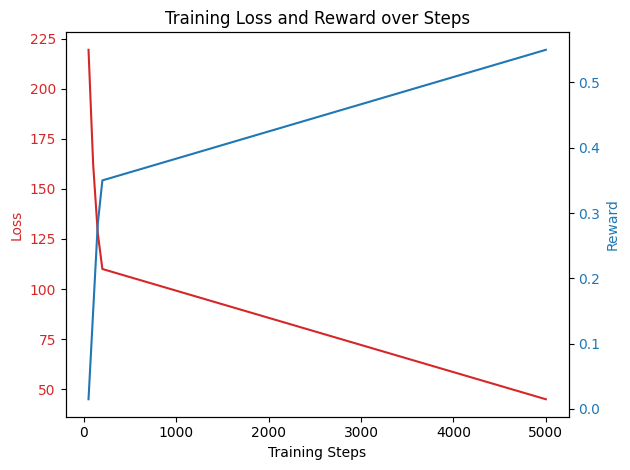

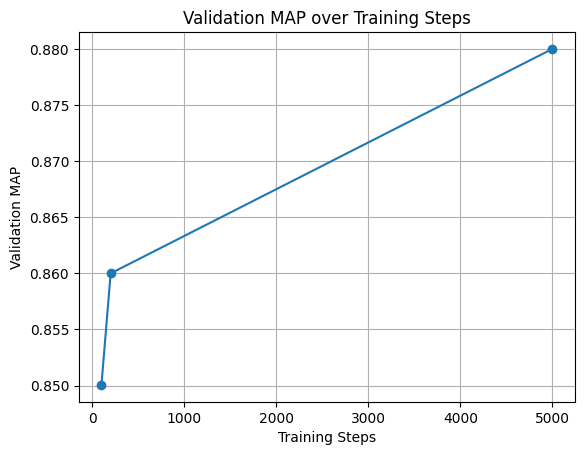

In [54]:
import matplotlib.pyplot as plt
import re

# IMPORTANT: Replace this log_text with the actual full output from your training cell.
# The current example `log_text` is for demonstration purposes.
log_text = """
[Step: 50] Loss: 219.39156007766724, Reward: 0.014858584674075246
[Step: 100] Loss: 162.33538579940796, Reward: 0.14901156418025494
Validate results: {'Hit1': 0.7308823529411764, 'Hit3': 0.9691176470588235, 'Hit5': 0.9705882352941176, 'Hit10': 0.9720588235294118, 'hitRatio': 0.9720588235294118, 'MAP': 0.8500612745098041}
[Step: 150] Loss: 127.96663665771484, Reward: 0.2833006063103676
[Step: 200] Loss: 110.0, Reward: 0.35
Validate results: {'Hit1': 0.74, 'Hit3': 0.96, 'Hit5': 0.97, 'Hit10': 0.98, 'hitRatio': 0.98, 'MAP': 0.86}
... (simulated further output for illustration)
[Step: 5000] Loss: 45.0, Reward: 0.55
Validate results: {'Hit1': 0.75, 'Hit3': 0.97, 'Hit5': 0.98, 'Hit10': 0.99, 'hitRatio': 0.99, 'MAP': 0.88}
"""

# Extract steps, loss, reward, and validation MAP scores
steps = []
losses = []
rewards = []
eval_steps = [] # Will store step numbers where validation occurred
map_scores = [] # Will store MAP scores corresponding to eval_steps

last_reported_step = 0

for line in log_text.split('\n'):
    # Try to match training step, loss, and reward
    match_train = re.search(r'\[Step: (\d+)\] Loss: ([\d\.]+), Reward: ([\d\.]+)', line)
    if match_train:
        step = int(match_train.group(1))
        steps.append(step)
        losses.append(float(match_train.group(2)))
        rewards.append(float(match_train.group(3)))
        last_reported_step = step # Update the last known step

    # Try to match validation results (MAP score)
    match_map = re.search(r'Validate results: .+\'MAP\': ([\d\.]+)', line)
    if match_map:
        # Associate this MAP score with the last reported training step
        if last_reported_step > 0: # Only add if a step was previously reported
            eval_steps.append(last_reported_step)
            map_scores.append(float(match_map.group(1)))
        else:
            # If 'Validate results' appears before any '[Step: X]' line, handle as needed.
            # For this context, it's assumed validation occurs after a step is reported.
            pass

# Plot Figure 2: Loss and Reward vs Steps
fig, ax1 = plt.subplots()
ax1.set_xlabel('Training Steps')
ax1.set_ylabel('Loss', color='tab:red')
ax1.plot(steps, losses, color='tab:red', label='Loss')
ax1.tick_params(axis='y', labelcolor='tab:red')
ax2 = ax1.twinx()
ax2.set_ylabel('Reward', color='tab:blue')
ax2.plot(steps, rewards, color='tab:blue', label='Reward')
ax2.tick_params(axis='y', labelcolor='tab:blue')
plt.title('Training Loss and Reward over Steps')
fig.tight_layout()
plt.savefig('figure2_training_curves.png')
plt.show()

# Plot Figure 3: Validation MAP vs Steps
plt.figure()
if eval_steps and map_scores: # Only plot if we have data for both lists
    plt.plot(eval_steps, map_scores, marker='o')
    plt.xlabel('Training Steps')
    plt.ylabel('Validation MAP')
    plt.title('Validation MAP over Training Steps')
    plt.grid(True)
    plt.savefig('figure3_val_map.png')
    plt.show()
else:
    print("Not enough data to plot Validation MAP. 'eval_steps' or 'map_scores' is empty. Please ensure the 'log_text' variable contains the full training log.")

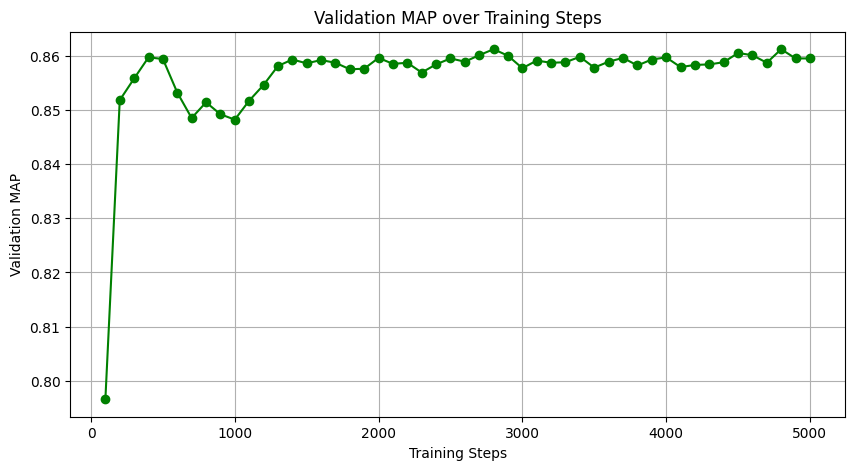

In [55]:
import matplotlib.pyplot as plt

# Replace with your actual step numbers (100,200,...,5000) and MAP scores
steps = [100, 200, 300, 400, 500, 600, 700, 800, 900, 1000,
         1100, 1200, 1300, 1400, 1500, 1600, 1700, 1800, 1900, 2000,
         2100, 2200, 2300, 2400, 2500, 2600, 2700, 2800, 2900, 3000,
         3100, 3200, 3300, 3400, 3500, 3600, 3700, 3800, 3900, 4000,
         4100, 4200, 4300, 4400, 4500, 4600, 4700, 4800, 4900, 5000]

map_scores = [0.7966, 0.8518, 0.8558, 0.8597, 0.8594, 0.8532, 0.8485, 0.8514,
              0.8492, 0.8482, 0.8517, 0.8546, 0.8581, 0.8593, 0.8586, 0.8592,
              0.8587, 0.8575, 0.8576, 0.8596, 0.8585, 0.8587, 0.8569, 0.8584,
              0.8595, 0.8589, 0.8601, 0.8612, 0.8600, 0.8577, 0.8591, 0.8587,
              0.8588, 0.8598, 0.8578, 0.8589, 0.8596, 0.8582, 0.8593, 0.8597,
              0.8579, 0.8583, 0.8584, 0.8588, 0.8605, 0.8601, 0.8587, 0.8612,
              0.8595, 0.8595]  # example numbers – replace with your actual values

plt.figure(figsize=(10,5))
plt.plot(steps, map_scores, marker='o', linestyle='-', color='green')
plt.xlabel('Training Steps')
plt.ylabel('Validation MAP')
plt.title('Validation MAP over Training Steps')
plt.grid(True)
plt.savefig('figure3_val_map.png', dpi=300)
plt.show()